# Tutorial 16: Inverse Design by ML Screening

In Tutorials 11-13 we started from a layout and asked for its capacitance matrix. In a real design job it is usually the other way round: we are given target numbers (a charging energy, a few coupling capacitances) and need a layout that hits them. In this tutorial we walk through the two examples of the "Practical workflows" section of our paper, using only public SQuADDS APIs:

| example | targets | search |
|---|---|---|
| an Xmon | $E_C$ and the claw coupling $C_{NS}$, at three targets | random screen, best pick per target |
| a TransmonPocket with readout, bus and drive couplers | four at once | random screen, then a few rounds of refinement around the best candidates |

Why not hand the targets to an inverse-design optimizer? That needs a fast, accurate model of how the layout parameters map to the circuit, and a good idea of which parameters matter and over what range. For a new component neither is easy to come by. The capacitance model gives an accurate matrix in about a second to a few seconds per layout on one CPU core, so we can skip that problem: try thousands of random layouts within sensible bounds, keep the best, and spend one expensive Q3D run on the winner to confirm it.

**Note:** the ML models need the optional extras, `pip install "squadds[ml,gds]"`. Xmon and TransmonPocket are families the released model was trained on, so this tutorial shows a design workflow, not the model's accuracy on new kinds of layouts (the random candidates we generate are, of course, new layouts).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

## Setup

We use quantum-metal without its GUI, and silence its (many) deprecation warnings.

In [2]:
import os
import tempfile
import time
import warnings
from collections import Counter
from pathlib import Path

os.environ.setdefault("QISKIT_METAL_HEADLESS", "1")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from qiskit_metal import Dict, designs
from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket

from squadds.components.xmon import Xmon
from squadds.layouts import export_dataset_gds
from squadds.ml.capacitance import CapacitancePredictor, inspect_layout, prepare_layout
from squadds.ml.capacitance.bridge import EC_MHz_from_matrix

set_matplotlib_formats("png")
pd.set_option("display.width", 160)

### How big a search?

The paper screened 5,000 layouts per example on a cluster, a few CPU-hours. By default this notebook runs a smaller version that finishes in about 12 minutes on a laptop (Apple M5 Pro, 8 processes). Set the knobs below to the paper's values (in the comments) to run the full size. On the same laptop that takes about two hours.

| knob | this notebook | paper |
|---|---|---|
| `N_XMON`: random Xmon layouts | 1,000 | 5,000 |
| `N_POCKET`: random TransmonPocket layouts | 300 | 5,000 |
| `TOP` x `PER`: parents per round x (parent + variants) | 10 x 8 | 20 x 50 in round 1, 20 x 40 after |
| `JITTER`: size of the random changes per round | 1, 1, 1, 0.2 | 1, 1, 1, 0.2 (four rounds) |

`WORKERS` processes run at once, each with `THREADS` CPU threads. `WORKERS` is 8, or the number of CPUs this process may use when that is fewer (under Slurm or in a container, the job's allocation, not the node's cores).

In [3]:
N_XMON = 1000  # paper: 5000
N_POCKET = 300  # paper: 5000
TOP, PER = 10, 8  # paper: 20, 50 (round 1) then 40
JITTER = [1.0, 1.0, 1.0, 0.2]  # one entry per refinement round
CPUS = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)  # this job's CPUs (Slurm, containers)
WORKERS, THREADS = min(8, CPUS), 1
SEED = 16
WORKDIR = Path(tempfile.mkdtemp(prefix="tutorial16_"))  # thousands of small GDS files; point it elsewhere to keep them
WORKDIR

PosixPath('/var/folders/s5/b9svd25j78scrd1kw84_tcs00000gn/T/tutorial16_5_9u1xro')

We use the default model, `QCap`, for every score in this tutorial:

In [4]:
predictor = CapacitancePredictor("QCap", threads=THREADS)
predictor

CapacitancePredictor('QCap', threads=1)

`predictor.predict` takes a list of layouts and, with `workers > 1`, predicts them in that many processes at once. Here is a small wrapper that also records what each batch cost. Every result carries its own timing, thread count and machine, so we print those rather than guess them.

The per-layout time is the model's own work (embedding, the two field solves of the physics prior, the networks). The wall time also counts starting the processes and loading the model in each.

In [5]:
COST = []


def predict_all(layouts, stage):
    t0 = time.perf_counter()
    results = predictor.predict(layouts, workers=WORKERS)
    wall = time.perf_counter() - t0
    per = np.array([r.timing_s["total_s"] for r in results])
    COST.append({"stage": stage, "layouts": len(results), "wall (min)": wall / 60, "processes": WORKERS,
                 "threads each": results[0].threads, "per layout, median (s)": np.median(per),
                 "per layout, p90 (s)": np.percentile(per, 90)})
    print(f"{stage}: {len(results)} layouts in {wall / 60:.1f} min wall time ({WORKERS} processes x "
          f"{results[0].threads} thread) | per layout: median {np.median(per):.2f} s, p90 {np.percentile(per, 90):.2f} s")
    return results

One more helper: a quick design-rule check. A random layout can put two pieces of metal on top of each other or closer than we could fabricate, and such a layout would silently have fewer conductors. We keep a layout only if it has the conductors we expect and every gap (conductor-conductor and conductor-ground) is at least 2 µm, the rule the paper's generator used.

In [6]:
MIN_GAP_UM = 1.99


def check_layout(gds, n_conductors):
    # The prepared layout (ground + conductor bodies) that the predictor will read, if it passes the checks.
    lay = prepare_layout(str(gds))
    bodies = list(lay.conductors)
    if len(bodies) != n_conductors:
        raise ValueError(f"{len(bodies)} conductors instead of {n_conductors}")
    gaps = [a.distance(b) for i, a in enumerate(bodies) for b in bodies[i + 1:]] + [b.distance(lay.ground) for b in bodies]
    if min(gaps) < MIN_GAP_UM:
        raise ValueError("minimum gap below 2 um")
    return lay

## Example 1: Xmon screening

An Xmon is a cross (the qubit island, whose junction goes to ground) in a ground pocket, with a claw that couples it to a readout resonator. From the predicted Maxwell matrix we need two numbers:

- the charging energy $E_C = e^2 / 2hC_{SS}$, where $C_{SS}$ is the cross's diagonal entry (so every claw counts), and

- the claw coupling $C_{NS}$, minus the Maxwell entry between the claw and the cross.

We want three Xmons:

| target | $E_C$ (MHz) | $C_{NS}$ (fF) |
|---|---|---|
| 1 | 200 | 3 |
| 2 | 250 | 4 |
| 3 | 300 | 2 |

and score a candidate by its summed relative distance to a target, $|E_C/E_C^{\rm t} - 1| + |C_{NS}/C_{NS}^{\rm t} - 1|$.

### A random Xmon generator

We draw every parameter uniformly within the bounds of the paper's pool (µm):

| parameter | range |
|---|---|
| `cross_length` | 120-320 |
| `cross_width`, `cross_gap` | 16-40 |
| `claw_length` | 30 to min(`cross_length`, 220) |
| `claw_width` | 8-20 |
| `claw_gap` | 4-10 |
| `ground_spacing` | 4-12 |
| `claw_cpw_length` | 20-60 |
| second claw (half of the layouts) | same claw on the west or east arm, length 30 to min(`cross_length`, 220) |

The layout is SQuADDS' `Xmon` component, exported with `export_dataset_gds`. That writes the GDS convention of the model's training data: ground on layer 1/0, conductors on 1/10, and the chip margin of the Xmon family.

<details>
<summary><b>One difference from the paper's Xmon pool</b></summary>

`Xmon` draws the claw's feed line as in the training data (`claw_cpw_width`, 10 µm, wide). The paper's pool came from a development build of quantum-metal whose feed is `claw_width` wide and a few µm shorter, so the same parameters give a slightly different layout. On one design, the same model put the two versions 0.29 % (0.58 MHz) apart on $E_C$ and 0.47 % (0.014 fF) on $C_{NS}$.

</details>

In [7]:
def um(v):
    return f"{v:.3f}um"


def sample_xmon(rng):
    cl = rng.uniform(120, 320)
    p = {"cross_length": cl, "cross_width": rng.uniform(16, 40), "cross_gap": rng.uniform(16, 40),
         "claw_length": rng.uniform(30, min(cl, 220)), "claw_width": rng.uniform(8, 20), "claw_gap": rng.uniform(4, 10),
         "ground_spacing": rng.uniform(4, 12), "claw_cpw_length": rng.uniform(20, 60),
         "second_claw": bool(rng.random() < 0.5), "second_claw_location": str(rng.choice(["0", "180", "270"]))}
    p["second_claw_length"] = rng.uniform(30, min(cl, 220))
    return p


def build_xmon(p, path):
    def claw(length, location):
        return Dict(connector_location=location, connector_type="0", claw_length=um(length),
                    claw_width=um(p["claw_width"]), claw_gap=um(p["claw_gap"]), ground_spacing=um(p["ground_spacing"]),
                    claw_cpw_length=um(p["claw_cpw_length"]), claw_cpw_width="10um")

    pads = Dict(readout=claw(p["claw_length"], "90"))
    if p["second_claw"]:
        pads["bus"] = claw(p["second_claw_length"], p["second_claw_location"])
    design = designs.DesignPlanar({}, overwrite_enabled=True)
    xmon = Xmon(design, "xmon", options=Dict(cross_length=um(p["cross_length"]), cross_width=um(p["cross_width"]),
                                             cross_gap=um(p["cross_gap"]), connection_pads=pads))
    # the chip margin is 8 ground gaps, from the unrounded parameters as the paper's generator did
    return export_dataset_gds(xmon, path, ground_gap_um=max(p["cross_gap"], p["ground_spacing"]))

Let's build one and look at it before we build a thousand. `inspect_layout` shows the layout the way the predictor reads it: the ground in grey and every conductor body with the name the prediction will use. The export writes the conductors in the dataset's order, so `C1` is the readout claw (N), `C2` the cross (S) and `C3`, if there is one, the second claw.

['C1', 'C2', 'C3']

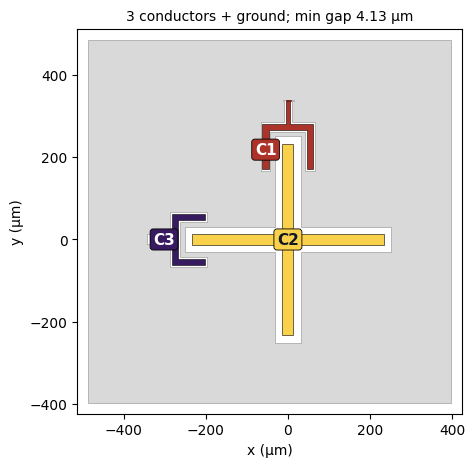

In [8]:
rng = np.random.default_rng(SEED)
example = sample_xmon(rng)
example_gds = build_xmon(example, WORKDIR / "xmon_example.gds")
view = inspect_layout(str(example_gds), figsize=(5, 5))
view["names"]

### Generate the pool

Now the whole pool. Layouts that fail the export (the ground breaks into pieces) or the design-rule check are redrawn, and we count why.

In [9]:
rng = np.random.default_rng(SEED)
xmon_params, xmon_layouts, rejected = [], [], Counter()
(WORKDIR / "xmon").mkdir(exist_ok=True)
t0 = time.perf_counter()
while len(xmon_layouts) < N_XMON:
    p = sample_xmon(rng)
    try:
        gds = build_xmon(p, WORKDIR / "xmon" / f"xmon_{len(xmon_layouts):04d}.gds")
        lay = check_layout(gds, 3 if p["second_claw"] else 2)
    except Exception as err:
        rejected[str(err).split("(")[0].strip()] += 1
        continue
    xmon_params.append(p)
    xmon_layouts.append(lay)
print(f"{len(xmon_layouts)} layouts in {time.perf_counter() - t0:.0f} s (one process); rejected: {dict(rejected)}")

1000 layouts in 42 s (one process); rejected: {'2 conductors instead of 3': 8, 'ground is not one connected body': 39}


### Predict all of them

One call, `WORKERS` processes:

In [10]:
xmon_results = predict_all(xmon_layouts, "Xmon screen")
print(xmon_results[0].machine)

Xmon screen: 1000 layouts in 1.7 min wall time (8 processes x 1 thread) | per layout: median 0.71 s, p90 1.21 s
Apple M5 Pro, 18 CPUs, Darwin arm64


Every result is a full Maxwell matrix (fF, ground first). Let's turn each into $E_C$ and $C_{NS}$. `EC_MHz_from_matrix` takes the cross's diagonal entry for a grounded transmon:

In [11]:
def xmon_quantities(res):
    M, names = res.matrix_fF, res.names
    return {"E_C (MHz)": EC_MHz_from_matrix(M, names, "C2"), "C_NS (fF)": -M[names.index("C1"), names.index("C2")]}


xmon = pd.DataFrame([xmon_quantities(r) for r in xmon_results]).join(pd.DataFrame(xmon_params))
print("every matrix passed its physics checks:", all(r.checks["passed"] for r in xmon_results))
xmon[["E_C (MHz)", "C_NS (fF)"]].describe().round(2)

every matrix passed its physics checks: True


,E_C (MHz),C_NS (fF)
count,1000.00,1000.00
mean,183.72,3.00
std,60.11,1.50
min,90.01,0.66
25%,136.15,1.82
50%,168.21,2.70
75%,223.08,3.97
max,377.94,9.70


### Pick the best candidate per target

In [12]:
XMON_TARGETS = [(200.0, 3.0), (250.0, 4.0), (300.0, 2.0)]


def xmon_loss(df, ec, cns):
    return (df["E_C (MHz)"] / ec - 1).abs() + (df["C_NS (fF)"] / cns - 1).abs()


rows = []
for ec, cns in XMON_TARGETS:
    loss = xmon_loss(xmon, ec, cns)
    i = loss.idxmin()
    r = xmon.loc[i]
    rows.append({"target E_C (MHz)": ec, "target C_NS (fF)": cns, "layout": i,
                 "E_C (MHz)": r["E_C (MHz)"], "E_C - target (MHz)": r["E_C (MHz)"] - ec,
                 "E_C - target (%)": 100 * (r["E_C (MHz)"] / ec - 1),
                 "C_NS (fF)": r["C_NS (fF)"], "C_NS - target (fF)": r["C_NS (fF)"] - cns,
                 "C_NS - target (%)": 100 * (r["C_NS (fF)"] / cns - 1), "loss": loss[i],
                 "within 2 % of both": int((loss < 0.02).sum())})
xmon_picks = pd.DataFrame(rows)
xmon_picks.round(3)

,target E_C (MHz),target C_NS (fF),layout,E_C (MHz),E_C - target (MHz),E_C - target (%),C_NS (fF),C_NS - target (fF),C_NS - target (%),loss,within 2 % of both
0,200.0,3.0,473,198.250,-1.750,-0.875,3.043,0.043,1.434,0.023,0
1,250.0,4.0,996,257.803,7.803,3.121,3.973,-0.027,-0.671,0.038,0
2,300.0,2.0,827,300.715,0.715,0.238,1.984,-0.016,-0.800,0.010,2


These are the model's numbers for its picks, so the distance to the target here is a property of the pool. With random sampling, a target in a sparse corner of the $(C_{NS}, E_C)$ plane gets a worse pick. The last column counts how many layouts of the pool land within a summed 2 % of each target. Let's see where the pool sits:

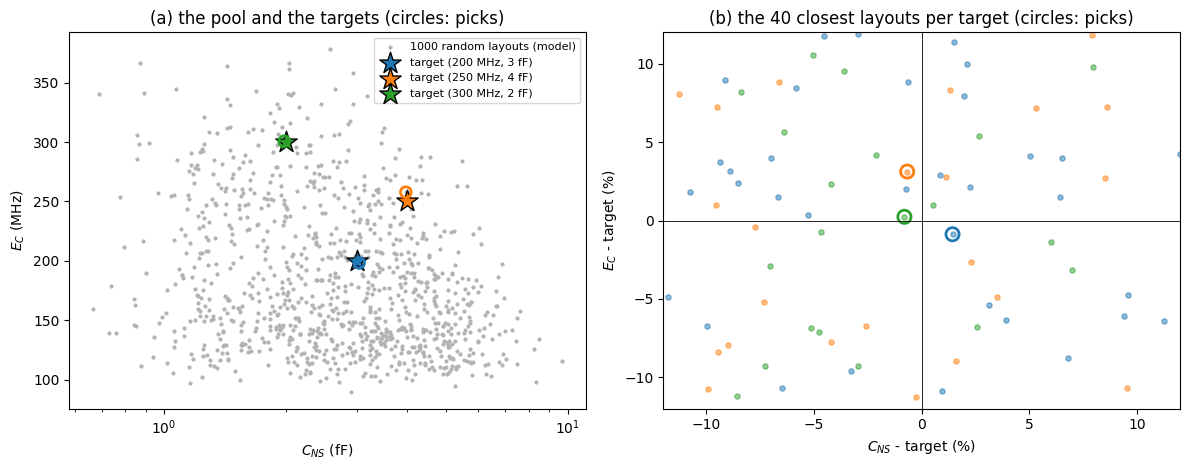

In [13]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(12, 4.8))
ax.scatter(xmon["C_NS (fF)"], xmon["E_C (MHz)"], s=4, color="0.7", label=f"{len(xmon)} random layouts (model)")
colors = ["tab:blue", "tab:orange", "tab:green"]
for (ec, cns), (_, pk), c in zip(XMON_TARGETS, xmon_picks.iterrows(), colors):
    ax.scatter(cns, ec, marker="*", s=260, color=c, edgecolor="k", zorder=3, label=f"target ({ec:.0f} MHz, {cns:.0f} fF)")
    ax.scatter(pk["C_NS (fF)"], pk["E_C (MHz)"], s=60, facecolor="none", edgecolor=c, lw=2, zorder=3)
    near = xmon.assign(loss=xmon_loss(xmon, ec, cns)).nsmallest(40, "loss")
    bx.scatter(100 * (near["C_NS (fF)"] / cns - 1), 100 * (near["E_C (MHz)"] / ec - 1), s=14, color=c, alpha=0.5)
    bx.scatter(pk["C_NS - target (%)"], pk["E_C - target (%)"], s=90, facecolor="none", edgecolor=c, lw=2)
ax.set(xscale="log", xlabel="$C_{NS}$ (fF)", ylabel="$E_C$ (MHz)", title="(a) the pool and the targets (circles: picks)")
ax.legend(fontsize=8, loc="upper right")
bx.axhline(0, color="k", lw=0.6)
bx.axvline(0, color="k", lw=0.6)
bx.set(xlim=(-12, 12), ylim=(-12, 12), xlabel="$C_{NS}$ - target (%)", ylabel="$E_C$ - target (%)",
       title="(b) the 40 closest layouts per target (circles: picks)")
fig.tight_layout()

And the three picked layouts (`C1` claw, `C2` cross, `C3` second claw):

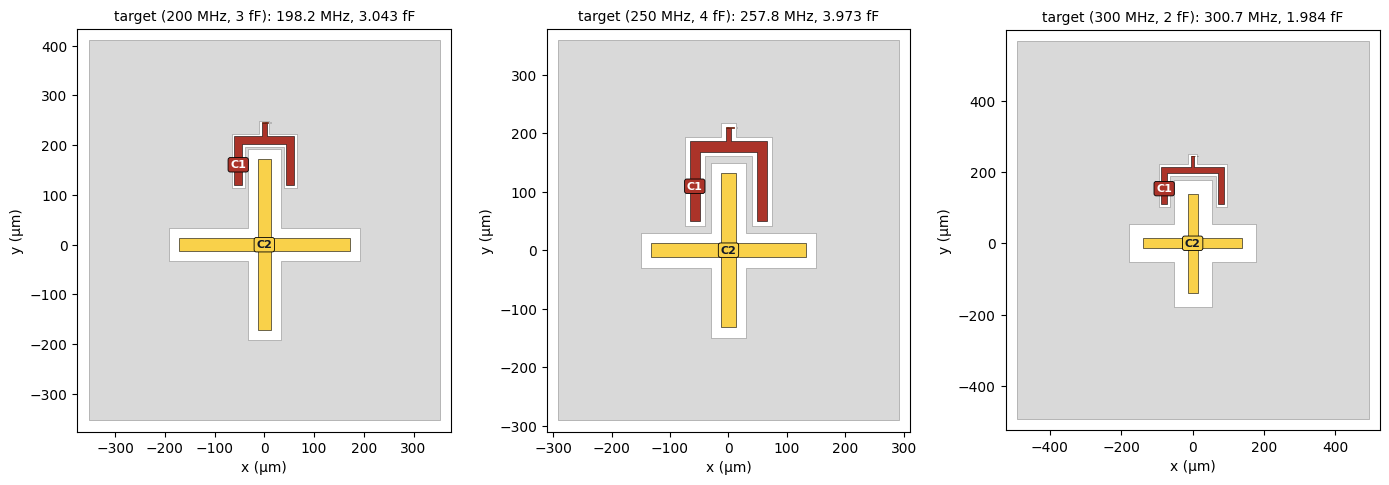

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (_, pk) in zip(axes, xmon_picks.iterrows()):
    xmon_layouts[int(pk["layout"])].render(ax=ax, compact=True)
    ax.set_title(f"target ({pk['target E_C (MHz)']:.0f} MHz, {pk['target C_NS (fF)']:.0f} fF): "
                 f"{pk['E_C (MHz)']:.1f} MHz, {pk['C_NS (fF)']:.3f} fF", fontsize=10)
fig.tight_layout()

The parameters of the picks, ready to go into a quantum-metal design:

In [15]:
xmon.loc[xmon_picks["layout"], list(xmon_params[0])].round(2)

,cross_length,cross_width,cross_gap,claw_length,claw_width,claw_gap,ground_spacing,claw_cpw_length,second_claw,second_claw_location,second_claw_length
473,171.31,26.90,20.18,82.99,16.18,5.20,5.44,26.00,False,180,83.76
996,131.78,24.24,17.69,118.59,17.30,8.23,11.01,23.33,False,180,100.68
827,139.15,27.90,39.29,88.48,15.65,7.78,11.07,30.45,False,270,83.80


### What Q3D said in the paper

We don't run Q3D here. In the paper, the three picks of the full 5,000-layout pool were solved in Ansys Q3D (16 cores of a cluster node, 18-19 adaptive passes, 5.3-7.2 min each). The table below holds **the paper's numbers**, not recomputed in this notebook.

<details>
<summary><b>Why the model column of the paper's table differs slightly from the released model</b></summary>

The model column is the version of QCap that was deployed when the study ran (October 2026). The released model's networks have been retrained since, so they give slightly different numbers for the same layout.

</details>

In [16]:
paper_xmon = pd.DataFrame(
    {"target E_C (MHz)": [200.0, 250.0, 300.0], "target C_NS (fF)": [3.0, 4.0, 2.0],
     "model E_C (MHz)": [199.934, 246.239, 296.987], "model C_NS (fF)": [3.0396, 3.9819, 1.9524],
     "Q3D E_C (MHz)": [200.345, 246.632, 296.747], "Q3D C_NS (fF)": [3.0432, 3.9710, 1.9491]},
    index=pd.Index(["2659", "2073", "2147"], name="paper pick"))


def paper_table(df, quantities):
    out = {}
    for q, unit in quantities:
        t, m, s = df[f"target {q} ({unit})"], df[f"model {q} ({unit})"], df[f"Q3D {q} ({unit})"]
        out[f"{q}: Q3D - target ({unit})"] = s - t
        out[f"{q}: Q3D - target (%)"] = 100 * (s / t - 1)
        out[f"{q}: model - Q3D ({unit})"] = m - s
        out[f"{q}: model - Q3D (%)"] = 100 * (m / s - 1)
    return pd.DataFrame(out, index=df.index)


def summary(table, quantities):
    for q, unit in quantities:
        for what in ("Q3D - target", "model - Q3D"):
            d, pct = table[f"{q}: {what} ({unit})"], table[f"{q}: {what} (%)"].abs()
            print(f"{q:>9} {what:>13}: median {pct.median():.2f} % | MAE {d.abs().mean():.4g} {unit} | "
                  f"RMSE {np.sqrt((d ** 2).mean()):.4g} {unit} | max {pct.max():.2f} %")


XQ = [("E_C", "MHz"), ("C_NS", "fF")]
xmon_q3d = paper_table(paper_xmon, XQ)
display(xmon_q3d.round(4))
summary(xmon_q3d, XQ)

,E_C: Q3D - target (MHz),E_C: Q3D - target (%),E_C: model - Q3D (MHz),E_C: model - Q3D (%),C_NS: Q3D - target (fF),C_NS: Q3D - target (%),C_NS: model - Q3D (fF),C_NS: model - Q3D (%)
paper pick,,,,,,,,
2659,0.345,0.1725,-0.411,-0.2051,0.0432,1.440,-0.0036,-0.1183
2073,-3.368,-1.3472,-0.393,-0.1593,-0.0290,-0.725,0.0109,0.2745
2147,-3.253,-1.0843,0.240,0.0809,-0.0509,-2.545,0.0033,0.1693


      E_C  Q3D - target: median 1.08 % | MAE 2.322 MHz | RMSE 2.711 MHz | max 1.35 %
      E_C   model - Q3D: median 0.16 % | MAE 0.348 MHz | RMSE 0.3564 MHz | max 0.21 %
     C_NS  Q3D - target: median 1.44 % | MAE 0.04103 fF | RMSE 0.04202 fF | max 2.54 %
     C_NS   model - Q3D: median 0.17 % | MAE 0.005933 fF | RMSE 0.006896 fF | max 0.27 %


In Q3D, every pick landed close to its targets, and the model's error against Q3D is several times smaller than the distance of the picks to their targets (compare the medians above). The larger misses of the second and third targets were already in the model's prediction of its own pick, because the pool had no closer layout. A denser pool would close them, as panel (b) above suggests.

## Example 2: a TransmonPocket with three couplers

Now a harder problem. A `TransmonPocket` has two floating pads (the qubit is the voltage difference between them) and here three connection pads: a **readout** coupler and a **bus** coupler on top, a **drive** coupler at the bottom. With the ground, that is six conductors and a full 6 x 6 matrix. We want four things at once:

| quantity | target |
|---|---|
| $E_C$ of the qubit | 200 MHz |
| $C_{\rm eff}$ to the readout | 10 fF |
| $C_{\rm eff}$ to the bus | 1 fF |
| $C_{\rm eff}$ to the drive | 0.1 fF |

The three couplings span a factor of 100 and every one of them also changes $E_C$, so it is hard to guess good parameter bounds up front.

### The quantities of a floating transmon

With the couplers held at ground, the qubit is the differential mode of the two pads $s$ and $b$. Eliminating their common mode (a Schur complement of the 2 x 2 pad block of the Maxwell matrix) leaves one capacitance for the qubit,

$$C_\Sigma = \frac{C_{ss}C_{bb} - C_{sb}^2}{C_{ss} + C_{bb} + 2C_{sb}}, \qquad E_C = \frac{e^2}{2hC_\Sigma},$$

and coupler $k$, which sees the two pads through $c_{ks}$ and $c_{kb}$, couples to that mode with

$$C_{{\rm eff},k} = \frac{|c_{ks}C_{b\Sigma} - c_{kb}C_{s\Sigma}|}{C_{s\Sigma} + C_{b\Sigma}}, \qquad C_{s\Sigma} = C_{ss} + C_{sb},\quad C_{b\Sigma} = C_{bb} + C_{sb}.$$

All entries are Maxwell entries ($C_{sb}$ and the $c$'s are negative). A coupler that sees both pads equally does not couple to the qubit at all. What counts is the imbalance. The export writes the conductors in the order readout (`C1`), top pad (`C2`), bottom pad (`C3`), bus (`C4`), drive (`C5`).

In [17]:
P3_TARGETS = {"E_C (MHz)": 200.0, "readout (fF)": 10.0, "bus (fF)": 1.0, "drive (fF)": 0.1}
COUPLERS = {"readout": "C1", "bus": "C4", "drive": "C5"}


def pocket_quantities(res):
    M, names = res.matrix_fF, res.names
    s, b = names.index("C2"), names.index("C3")
    css, cbb, csb = M[s, s], M[b, b], M[s, b]
    s_sum, b_sum = css + csb, cbb + csb
    out = {"E_C (MHz)": EC_MHz_from_matrix(M, names, ["C2", "C3"])}
    for coupler, name in COUPLERS.items():
        k = names.index(name)
        out[f"{coupler} (fF)"] = abs(M[k, s] * b_sum - M[k, b] * s_sum) / (s_sum + b_sum)
    return out


def pocket_loss(df):
    return sum(np.abs(np.log(df[q] / t)) for q, t in P3_TARGETS.items())

`EC_MHz_from_matrix` with two pads computes the same $C_\Sigma$ (as $1/C_\Sigma = (C^{-1})_{ss} + (C^{-1})_{bb} - 2(C^{-1})_{sb}$ of the pad block). The loss is the summed $|\log(\text{predicted}/\text{target})|$ over the four quantities, so 0.01 means about 1 % off in total.

### A random TransmonPocket generator

This is the paper's generator, built from the `TransmonPocket` of quantum-metal with three `connection_pads` (µm; "log" = log-uniform):

| parameter | range |
|---|---|
| pad width, height, gap | 400-900, 100-320, 15-80 |
| readout coupler width, height, gap | 40 to 0.9 x pad width / 2 (log), 15-80, 3-40 (log) |
| bus coupler width, height, gap | 12-200 (log), 10-50, 5-90 (log) |
| drive coupler width, height, gap | 3-30 (log), 6-30, 60-500 (log) |
| pocket | pad width + 2 x (40-120) wide, tall enough for the couplers + 2 x (40-100) |
| drive side | left or right |

Exported with `export_dataset_gds`, the same parameters rebuild the paper's layouts polygon for polygon.

In [18]:
CPLRS = ("readout", "bus", "drive")


def sample_pocket(rng):
    pw, ph, pg = rng.uniform(400, 900), rng.uniform(100, 320), rng.uniform(15, 80)
    p = {"pad_width": pw, "pad_height": ph, "pad_gap": pg}
    w = {"readout": (40, 0.9 * pw / 2), "bus": (12, 200), "drive": (3, 30)}
    g = {"readout": (3, 40), "bus": (5, 90), "drive": (60, 500)}
    h = {"readout": (15, 80), "bus": (10, 50), "drive": (6, 30)}
    for c in CPLRS:
        p[f"{c}_w"] = float(np.exp(rng.uniform(*np.log(w[c]))))
        p[f"{c}_h"] = rng.uniform(*h[c])
        p[f"{c}_gap"] = float(np.exp(rng.uniform(*np.log(g[c]))))
    top = max(p["readout_h"] + p["readout_gap"], p["bus_h"] + p["bus_gap"])
    p["pocket_width"] = pw + 2 * rng.uniform(40, 120)
    p["pocket_height"] = pg + 2 * ph + 2 * (max(top, p["drive_h"] + p["drive_gap"]) + rng.uniform(40, 100))
    p["drive_loc_W"] = int(rng.choice([-1, 1]))
    return p

In [18]:
def build_pocket(p, path):
    side = {"readout": (1, 1), "bus": (-1, 1), "drive": (p["drive_loc_W"], -1)}
    pads = Dict({c: Dict(loc_W=str(side[c][0]), loc_H=str(side[c][1]), pad_width=um(p[f"{c}_w"]),
                         pad_height=um(p[f"{c}_h"]), pad_gap=um(p[f"{c}_gap"]), cpw_width="10um", cpw_gap="6um",
                         cpw_extend="60um") for c in CPLRS})
    design = designs.DesignPlanar({}, overwrite_enabled=True)
    pocket = TransmonPocket(design, "pocket", options=Dict(
        pad_width=um(p["pad_width"]), pad_height=um(p["pad_height"]), pad_gap=um(p["pad_gap"]),
        pocket_width=um(p["pocket_width"]), pocket_height=um(p["pocket_height"]), connection_pads=pads))
    # chip margin: 4 ground gaps, the pad-to-pocket gap (at least 20 um), as in the paper's generator
    gap = min((p["pocket_width"] - p["pad_width"]) / 2, (p["pocket_height"] - p["pad_gap"]) / 2 - p["pad_height"])
    return export_dataset_gds(pocket, path, ground_gap_um=max(gap, 20.0))


def build_pockets(params, folder):
    # Build and check a list of parameter sets: (kept params, prepared layouts, rejection counts).
    (WORKDIR / folder).mkdir(exist_ok=True)
    kept, layouts, rejected = [], [], Counter()
    for i, p in enumerate(params):
        try:
            layouts.append(check_layout(build_pocket(p, WORKDIR / folder / f"pocket_{i:04d}.gds"), 5))
            kept.append(p)
        except Exception as err:
            rejected[str(err).split("(")[0].strip()] += 1
    return kept, layouts, rejected

Let's look at one (`C1` readout, `C2` / `C3` the pads, `C4` bus, `C5` drive):

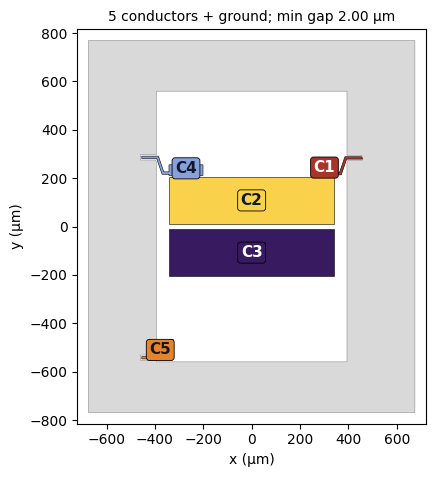

In [19]:
example = sample_pocket(np.random.default_rng(SEED))
view = inspect_layout(str(build_pocket(example, WORKDIR / "pocket_example.gds")), figsize=(4.5, 6))

### Step 1: screen random layouts

In [20]:
rng = np.random.default_rng(SEED)
t0 = time.perf_counter()
pocket_params, pocket_layouts, rejected = build_pockets([sample_pocket(rng) for _ in range(N_POCKET)], "pocket_screen")
print(f"{len(pocket_layouts)} layouts built in {time.perf_counter() - t0:.0f} s; rejected: {dict(rejected)}")
pocket_results = predict_all(pocket_layouts, "TransmonPocket screen")

300 layouts built in 24 s; rejected: {}


TransmonPocket screen: 300 layouts in 4.0 min wall time (8 processes x 1 thread) | per layout: median 5.90 s, p90 8.50 s


In [21]:
QCOLS = list(P3_TARGETS)
screen = pd.DataFrame([pocket_quantities(r) for r in pocket_results])
screen["loss"] = pocket_loss(screen)
screen["params"] = pocket_params
within10 = (np.abs(np.log(screen[QCOLS] / pd.Series(P3_TARGETS))) < np.log(1.1)).all(axis=1).sum()
print(f"best loss {screen.loss.min():.3f}; layouts within 10 % of all four targets: {within10}")
screen.nsmallest(5, "loss")[QCOLS + ["loss"]].round(4)

best loss 0.870; layouts within 10 % of all four targets: 0


,E_C (MHz),readout (fF),bus (fF),drive (fF),loss
38,266.7711,9.0458,1.1810,0.1370,0.8698
273,203.0406,10.5548,1.1307,0.2451,1.0884
176,177.8554,7.7540,1.2056,0.1889,1.1949
156,210.6467,10.0446,1.8950,0.1751,1.2557
174,154.1621,10.5360,1.5443,0.1724,1.2919


The random screen gets us close on one or two quantities at a time, but no layout fits all four. The paper's 5,000-layout screen did not find one within 10 % of all four either. So we refine.

### Step 2: refine around the best candidates

Each round takes the `TOP` best layouts and makes `PER - 1` variants of each, keeping the parent. A variant scales

- the pad width by $(E_C/E_C^{\rm t})^{1/2}$ (a bigger pad means a bigger $C_\Sigma$ and a smaller $E_C$),
- each coupler's width by $(C^{\rm t}_{\rm eff}/C_{\rm eff})^{0.7}$ (a wider coupler couples more),

times a random log-normal factor (5 % spread on the pad width, 15 % on the coupler widths, and 10 % on the coupler gaps), all scaled by that round's `JITTER`. The pocket is then resized to fit. The steps use the model's own prediction of the parent, so this is a crude Newton step plus noise. As in the paper, the last round uses five times smaller random changes.

In [22]:
def propose(parent, q, rng, jitter):
    # One variant of a parent layout (parameters p) with predicted quantities q.
    p = dict(parent)
    f_pad = (q["E_C (MHz)"] / P3_TARGETS["E_C (MHz)"]) ** 0.5 * np.exp(rng.normal(0, 0.05 * jitter))
    p["pad_width"] = float(np.clip(parent["pad_width"] * f_pad, 300, 1100))
    for c in CPLRS:
        f = (P3_TARGETS[f"{c} (fF)"] / q[f"{c} (fF)"]) ** 0.7 * np.exp(rng.normal(0, 0.15 * jitter))
        p[f"{c}_w"] = float(np.clip(parent[f"{c}_w"] * f, 3, 0.9 * p["pad_width"] / 2))
        p[f"{c}_gap"] = float(np.clip(parent[f"{c}_gap"] * np.exp(rng.normal(0, 0.1 * jitter)), 3, 600))
    top = max(p["readout_h"] + p["readout_gap"], p["bus_h"] + p["bus_gap"])
    p["pocket_width"] = p["pad_width"] + (parent["pocket_width"] - parent["pad_width"])
    p["pocket_height"] = p["pad_gap"] + 2 * p["pad_height"] + 2 * (max(top, p["drive_h"] + p["drive_gap"]) + 60)
    return p


stages = [screen.assign(stage="screen")]
current = screen
for k, jitter in enumerate(JITTER, 1):
    rng = np.random.default_rng(SEED + k)
    parents = current.nsmallest(TOP, "loss")
    variants = [propose(r["params"], r, rng, jitter) for _, r in parents.iterrows() for _ in range(PER - 1)]
    kept, layouts, rejected = build_pockets(variants, f"pocket_round{k}")
    results = predict_all(layouts, f"TransmonPocket round {k}")
    new = pd.DataFrame([pocket_quantities(r) for r in results])
    new["params"] = kept
    new["loss"] = pocket_loss(new)
    current = pd.concat([parents, new], ignore_index=True)  # the parents stay in the running
    stages.append(current.assign(stage=f"round {k}"))
    print(f"   round {k} (jitter {jitter}): {len(kept)} new, {sum(rejected.values())} rejected, best loss {current.loss.min():.4f}")

TransmonPocket round 1: 70 layouts in 1.3 min wall time (8 processes x 1 thread) | per layout: median 8.48 s, p90 10.17 s
   round 1 (jitter 1.0): 70 new, 0 rejected, best loss 0.3654


TransmonPocket round 2: 70 layouts in 1.2 min wall time (8 processes x 1 thread) | per layout: median 7.67 s, p90 9.18 s
   round 2 (jitter 1.0): 70 new, 0 rejected, best loss 0.1467


TransmonPocket round 3: 70 layouts in 1.3 min wall time (8 processes x 1 thread) | per layout: median 8.18 s, p90 9.56 s
   round 3 (jitter 1.0): 70 new, 0 rejected, best loss 0.1467


TransmonPocket round 4: 70 layouts in 1.1 min wall time (8 processes x 1 thread) | per layout: median 7.03 s, p90 9.25 s
   round 4 (jitter 0.2): 70 new, 0 rejected, best loss 0.0743


How the loss went down, round by round. Panel (b) follows the best layout of each stage on each of the four quantities:

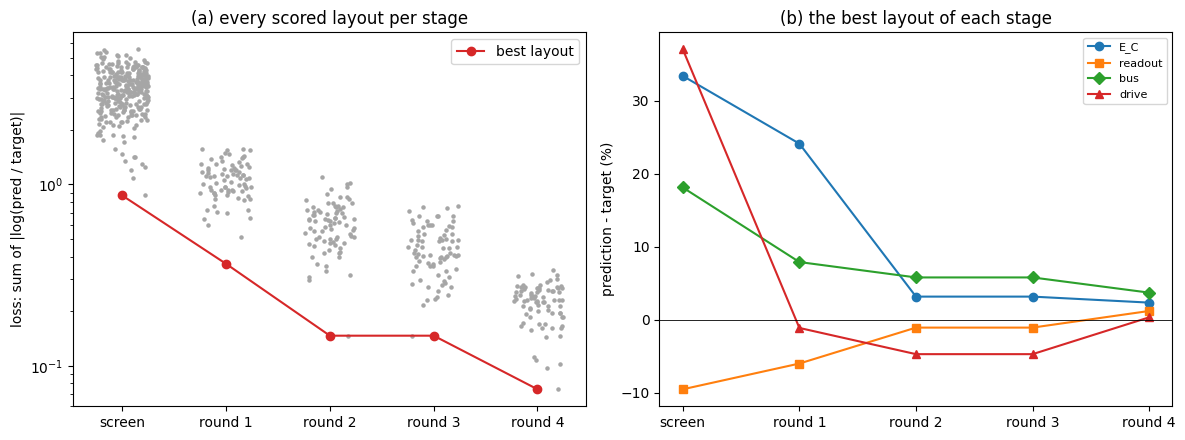

In [23]:
history = pd.concat(stages, ignore_index=True)
order = list(dict.fromkeys(history.stage))
best = history.loc[history.groupby("stage", sort=False).loss.idxmin()].set_index("stage").loc[order]

fig, (ax, bx) = plt.subplots(1, 2, figsize=(12, 4.5))
for i, st in enumerate(order):
    l = history.loc[history.stage == st, "loss"]
    ax.scatter(i + np.random.default_rng(i).uniform(-0.25, 0.25, len(l)), l, s=5, color="0.65")
ax.plot(range(len(order)), best.loss, "o-", color="tab:red", label="best layout")
ax.set(yscale="log", xticks=range(len(order)), xticklabels=order, ylabel="loss: sum of |log(pred / target)|",
       title="(a) every scored layout per stage")
ax.legend()
for q, m in zip(QCOLS, "osD^"):
    bx.plot(range(len(order)), 100 * (best[q] / P3_TARGETS[q] - 1), marker=m, label=q.split(" (")[0])
bx.axhline(0, color="k", lw=0.6)
bx.set(xticks=range(len(order)), xticklabels=order, ylabel="prediction - target (%)",
       title="(b) the best layout of each stage")
bx.legend(fontsize=8)
fig.tight_layout()

### The final pick

The best four distinct layouts of the last round, by the model:

In [24]:
final = current.assign(key=current.params.map(lambda p: tuple(sorted(p.items())))).drop_duplicates("key")
final = final.nsmallest(4, "loss").reset_index(drop=True)
pick_table = final[QCOLS + ["loss"]].copy()
for q, t in P3_TARGETS.items():
    unit = q.split("(")[1].rstrip(")")
    pick_table[f"{q.split(' (')[0]} - target ({unit})"] = final[q] - t
    pick_table[f"{q.split(' (')[0]} - target (%)"] = 100 * (final[q] / t - 1)
pick_table.round(4)

,E_C (MHz),readout (fF),bus (fF),drive (fF),loss,E_C - target (MHz),E_C - target (%),readout - target (fF),readout - target (%),bus - target (fF),bus - target (%),drive - target (fF),drive - target (%)
0,204.6619,10.1186,1.0370,0.1003,0.0743,4.6619,2.3309,0.1186,1.1861,0.0370,3.6972,0.0003,0.3145
1,204.6733,9.8433,0.9686,0.1026,0.0970,4.6733,2.3366,-0.1567,-1.5673,-0.0314,-3.1428,0.0026,2.6482
2,203.6652,10.1301,0.9998,0.1074,0.1030,3.6652,1.8326,0.1301,1.3011,-0.0002,-0.0241,0.0074,7.4266
3,205.5600,9.6343,1.0423,0.0998,0.1082,5.5600,2.7800,-0.3657,-3.6573,0.0423,4.2296,-0.0002,-0.2116


Our laptop-size search stops further from the targets than the paper's, whose four best layouts had a loss of 0.010-0.019 by the model. With 300 random layouts and 10 parents, every parent soon descends from the same few screen layouts. And when a coupler reaches the edge of the generator's range (a 3 µm wide drive coupler, or a 600 µm gap), the rule cannot push it any further. A bigger screen and more parents (the paper's 5,000 and 20) give the refinement more independent starting points. Here is how far the last round got, and whether any coupler sits at a limit:

In [25]:
best_params = final.loc[0, "params"]
at_limit = {k: round(v, 2) for k, v in best_params.items() if k.endswith(("_w", "_gap")) and (v <= 3.0 or v >= 600.0)}
print(f"best loss {final.loss[0]:.4f}; coupler widths / gaps at a limit: {at_limit or 'none'}")

best loss 0.0743; coupler widths / gaps at a limit: none


Its parameters, and its layout:

,final pick
pad_width,442.916
pad_height,262.392
pad_gap,27.168
readout_w,134.102
readout_h,60.845
readout_gap,4.844
bus_w,30.636
bus_h,20.339
bus_gap,88.215
drive_w,6.591


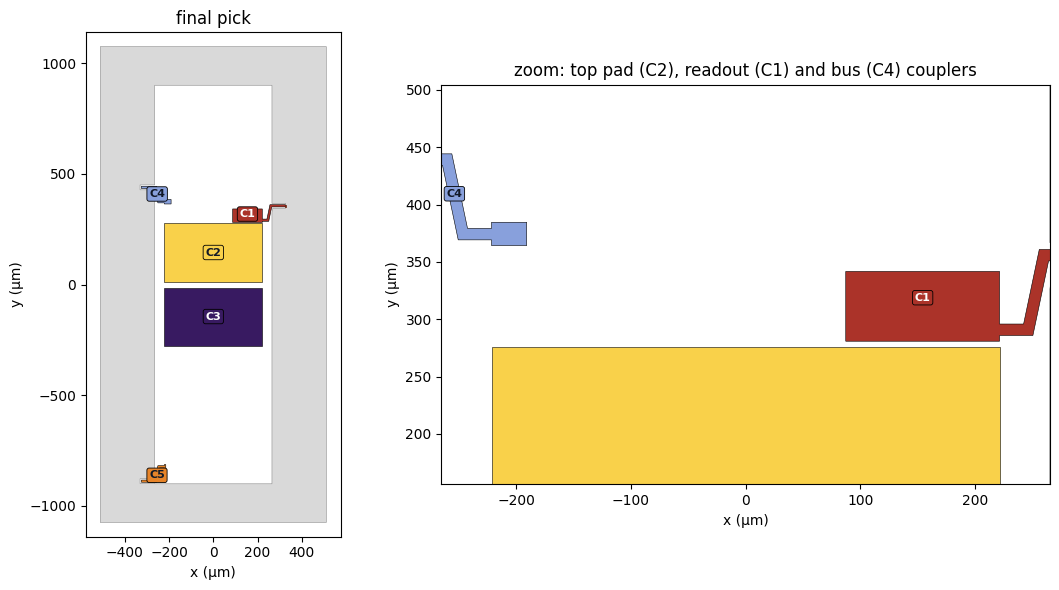

In [26]:
pocket_pick = final.loc[0, "params"]
display(pd.Series(pocket_pick).round(3).to_frame("final pick"))
pick_layout = check_layout(build_pocket(pocket_pick, WORKDIR / "pocket_final_pick.gds"), 5)
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={"width_ratios": [1, 1.6]})
pick_layout.render(ax=ax, compact=True)
pick_layout.render(ax=bx, compact=True)
top = pocket_pick["pad_gap"] / 2 + pocket_pick["pad_height"]
reach = max(pocket_pick["readout_h"] + pocket_pick["readout_gap"], pocket_pick["bus_h"] + pocket_pick["bus_gap"])
bx.set(xlim=(-pocket_pick["pocket_width"] / 2, pocket_pick["pocket_width"] / 2), ylim=(top - 120, top + reach + 120))
ax.set_title("final pick")
bx.set_title("zoom: top pad (C2), readout (C1) and bus (C4) couplers")
fig.tight_layout()

### What Q3D said in the paper

In the paper, the screen was followed by four rounds with 20 parents each. The four best layouts of the last rounds were solved in Q3D (16 cores of a cluster node, 17 passes, 5.5-6.3 min each), and the first of them, `fr4 0256`, is the paper's final candidate. These are **the paper's numbers**, not recomputed here. The model column is again the QCap version deployed at the time of the study.

In [27]:
paper_pocket = pd.DataFrame(
    {"target E_C (MHz)": 200.0, "target readout (fF)": 10.0, "target bus (fF)": 1.0, "target drive (fF)": 0.1,
     "model E_C (MHz)": [201.333, 199.820, 200.338, 199.285],
     "model readout (fF)": [10.0114, 10.0530, 10.0454, 9.9601],
     "model bus (fF)": [1.00056, 1.00051, 0.99541, 0.98920],
     "model drive (fF)": [0.100152, 0.100803, 0.100798, 0.099929],
     "Q3D E_C (MHz)": [200.973, 199.417, 199.981, 198.809],
     "Q3D readout (fF)": [9.99379, 10.01283, 10.02106, 9.96481],
     "Q3D bus (fF)": [0.998262, 0.998781, 0.994781, 0.989024],
     "Q3D drive (fF)": [0.101855, 0.103303, 0.101726, 0.102443]},
    index=pd.Index(["fr4 0256", "fr4 0084", "fr4 0052", "fr4 0496"], name="paper pick"))
PQ = [("E_C", "MHz"), ("readout", "fF"), ("bus", "fF"), ("drive", "fF")]
pocket_q3d = paper_table(paper_pocket, PQ)
display(pocket_q3d.round(4).T)
summary(pocket_q3d, PQ)

paper pick,fr4 0256,fr4 0084,fr4 0052,fr4 0496
E_C: Q3D - target (MHz),0.9730,-0.5830,-0.0190,-1.1910
E_C: Q3D - target (%),0.4865,-0.2915,-0.0095,-0.5955
E_C: model - Q3D (MHz),0.3600,0.4030,0.3570,0.4760
E_C: model - Q3D (%),0.1791,0.2021,0.1785,0.2394
readout: Q3D - target (fF),-0.0062,0.0128,0.0211,-0.0352
readout: Q3D - target (%),-0.0621,0.1283,0.2106,-0.3519
readout: model - Q3D (fF),0.0176,0.0402,0.0243,-0.0047
readout: model - Q3D (%),0.1762,0.4012,0.2429,-0.0473
bus: Q3D - target (fF),-0.0017,-0.0012,-0.0052,-0.0110
bus: Q3D - target (%),-0.1738,-0.1219,-0.5219,-1.0976


      E_C  Q3D - target: median 0.39 % | MAE 0.6915 MHz | RMSE 0.8224 MHz | max 0.60 %
      E_C   model - Q3D: median 0.19 % | MAE 0.399 MHz | RMSE 0.4019 MHz | max 0.24 %
  readout  Q3D - target: median 0.17 % | MAE 0.01882 fF | RMSE 0.02171 fF | max 0.35 %
  readout   model - Q3D: median 0.21 % | MAE 0.02171 fF | RMSE 0.02519 fF | max 0.40 %
      bus  Q3D - target: median 0.35 % | MAE 0.004788 fF | RMSE 0.006169 fF | max 1.10 %
      bus   model - Q3D: median 0.12 % | MAE 0.001208 fF | RMSE 0.001475 fF | max 0.23 %
    drive  Q3D - target: median 2.15 % | MAE 0.002332 fF | RMSE 0.002413 fF | max 3.30 %
    drive   model - Q3D: median 2.05 % | MAE 0.001911 fF | RMSE 0.002021 fF | max 2.45 %


In Q3D, every quantity of all four picks is within the paper's tolerance (2 % on $E_C$, 5 % on each coupling), the final candidate `fr4 0256` included. The drive coupling is the hardest to predict: 0.1 fF is a tiny entry, and its relative errors are the largest of the four.

Since the TransmonPocket generator rebuilds the paper's layouts exactly, we can also ask the released model about the paper's final candidate. Here are its parameters:

In [28]:
fr4_0256 = {"pad_width": 688.6380909870743, "pad_height": 130.6369775175318, "pad_gap": 40.421818353482784,
            "readout_w": 166.4378636685244, "readout_h": 50.55158510008755, "readout_gap": 6.586298346912528,
            "bus_w": 13.100040788537827, "bus_h": 17.168234251229094, "bus_gap": 42.50251313812672,
            "drive_w": 6.204543592956872, "drive_h": 23.15565208265336, "drive_gap": 533.9653419539899,
            "pocket_width": 782.7944415333966, "pocket_height": 1535.9377614618327, "drive_loc_W": 1}
res = predictor.predict(str(build_pocket(fr4_0256, WORKDIR / "paper_fr4_0256.gds")))
released = pd.Series(pocket_quantities(res))
compare = pd.DataFrame({"target": pd.Series(P3_TARGETS).values, "released model (this notebook)": released.values,
                        "paper: model": paper_pocket.iloc[0, 4:8].values, "paper: Q3D": paper_pocket.iloc[0, 8:12].values},
                       index=QCOLS)
compare["released - Q3D"] = compare["released model (this notebook)"] - compare["paper: Q3D"]
compare["released - Q3D (%)"] = 100 * compare["released - Q3D"] / compare["paper: Q3D"]
print(f"{res.timing_s['total_s']:.1f} s on {res.threads} thread, {res.machine}")
compare.round(4)

4.0 s on 1 thread, Apple M5 Pro, 18 CPUs, Darwin arm64


,target,released model (this notebook),paper: model,paper: Q3D,released - Q3D,released - Q3D (%)
E_C (MHz),200.0,201.4015,201.3330,200.9730,0.4285,0.2132
readout (fF),10.0,10.0037,10.0114,9.9938,0.0099,0.0988
bus (fF),1.0,0.9982,1.0006,0.9983,-0.0000,-0.0037
drive (fF),0.1,0.1016,0.1002,0.1019,-0.0003,-0.2507


This layout was built and solved after the released model was trained, so it is not in its training data. Still, one layout is a sanity check, not an accuracy score. The paper's accuracy tables are the score (see Tutorial 13 for the numbers).

## What it cost

Every batch of this notebook, on this machine:

In [29]:
cost = pd.DataFrame(COST).set_index("stage")
cost.loc["total"] = [cost.layouts.sum(), cost["wall (min)"].sum(), WORKERS, THREADS, np.nan, np.nan]
cost = cost.astype({"layouts": int, "processes": int, "threads each": int})
print(xmon_results[0].machine)
cost.round(2)

Apple M5 Pro, 18 CPUs, Darwin arm64


,layouts,wall (min),processes,threads each,"per layout, median (s)","per layout, p90 (s)"
stage,,,,,,
Xmon screen,1000,1.69,8,1,0.71,1.21
TransmonPocket screen,300,4.03,8,1,5.90,8.50
TransmonPocket round 1,70,1.32,8,1,8.48,10.17
TransmonPocket round 2,70,1.23,8,1,7.67,9.18
TransmonPocket round 3,70,1.26,8,1,8.18,9.56
TransmonPocket round 4,70,1.11,8,1,7.03,9.25
total,1580,10.65,8,1,NaN,NaN


For comparison, here are the paper's numbers. Generating the 5,000 Xmon layouts took about a minute on a laptop, and predicting them a few minutes of wall time over 64 processes of a cluster. The TransmonPocket screen of 5,000 took about 25 min on 64 CPUs of the cluster, the first two refinement rounds 12 min on 32 CPUs and the last two 21 min on a laptop with ten processes, about an hour in all. A Q3D solve of one such TransmonPocket took a median of 4.8 min on 16 cores, and the search needed only four of them at the end.

Congrats for making it to the end of this tutorial! You have now learned how to turn a capacitance model into a design tool: write a parametrised generator, screen a random pool in parallel, compute $E_C$ and effective couplings from the predicted matrix (including the differential mode of a floating transmon), refine around the best candidates, and render the winner. The model's pick is still a prediction: the layout you send to the fab deserves one real simulation, and that is the only one you need to run.

## Next Steps...

To screen a component family the model was not trained on, check it on a few of your own simulations first, and train on them if it falls short. [Tutorial 14](https://lfl-lab.github.io/SQuADDS/source/tutorials/Tutorial-14_Training_on_Your_Own_Designs.html) shows how.

## License

<div style='width: 100%; background-color:#3cb1c2;color:#324344;padding-left: 10px; padding-bottom: 10px; padding-right: 10px; padding-top: 5px'>
    <h3>This code is a part of SQuADDS</h3>
    <p>Developed by Sadman Ahmed Shanto</p>
    <p>This tutorial is written by Sadman Ahmed Shanto and Claude Opus 5.5</p>
    <p>&copy; Copyright Sadman Ahmed Shanto & Eli Levenson-Falk 2026.</p>
    <p>This code is licensed under the MIT License. You may<br> obtain a copy of this license in the LICENSE.txt file in the root directory<br> of this source tree.</p>
    <p>Any modifications or derivative works of this code must retain this<br>copyright notice, and modified files need to carry a notice indicating<br>that they have been altered from the originals.</p>
</div>